<a href="https://colab.research.google.com/github/ulises080/devopsUdemy/blob/master/Caso_Final_Evaluaci%C3%B3n%20de%20sentimientos_Ulises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CELDA 1 — Instalación de dependencias
# ============================================================
!pip install -q transformers datasets gensim scikit-learn matplotlib seaborn

# ============================================================
# CELDA 2 — Imports y configuración
# ============================================================
import os, re, random, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)

import torch
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 35.7 MB/s eta 0:00:00


In [ ]:
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED); torch.manual_seed(SEED)
sns.set_style("whitegrid")

In [ ]:
#Cargare el dataset de yelp con reseñas positivas y negativas en español, para entrenar un modelo de clasificacion de sentimientos

df_yelp = pd.read_csv('/mnt/datos_yelp_limpios.csv')
# Valido la carga del dataset
print(df_yelp.head())

print(f"\nDataset creado: {len(df_yelp)} resenas")
print(f"Distribucion: {df_yelp['sentimiento'].value_counts().to_dict()}")


#print(df_yelp.info())
df=df_yelp

#Cargado el dataset renombrare las columnas para que sean mas entendibles
#df_yelp.columns = ['sentiment', 'review']
#df_yelp['sentiment'] = df_yelp['sentiment'].map({1: 0, 2: 1})  # Mapear 1 a 0 (negativo) y 2 a 1 (positivo)
#print(df_yelp.head())
#Agregrare columna de longitud de reseña para analizar la distribucion de la longitud de las reseñas
#df_yelp['review_length'] = df_yelp['review'].apply(len)
#agregare columna de sentimiento como texto para analizar la distribucion de sentimientos
#df_yelp['sentiment_text'] = df_yelp['sentiment'].map({0: 'negative', 1: 'positive'})
#print("\nMuestra de los datos:\n",df_yelp.head())

   etiqueta                                             resena  review_length  \
0         0  When the rootbeer float I ordered imploded all...            569   
1         0  The place is pretty pretentious. There are for...            166   
2         0  My family and I came here by recommendation fr...           3342   
3         0  Extremely dissapointing! For $120 I expected a...            140   
4         0  I can remember when the restore was actually p...            199   

  sentiment_text sentimiento  
0       negative    negativo  
1       negative    negativo  
2       negative    negativo  
3       negative    negativo  
4       negative    negativo  

Dataset creado: 100000 resenas
Distribucion: {'negativo': 50000, 'positivo': 50000}


In [ ]:
# Limpieza de reseñas yelp

# FUNCION PARA LIMPIAR EL TEXTO DE LAS RESENAS, CONSEVANDO LOS ACENTOS Y ELIMINANDO LOS SIGNOS DE PUNTUACION Y CARACTERES ESPECIALES
def limpiar_texto(texto):
    """
    Limpia un texto en tres pasos:
    1. Convierte a minusculas
    2. Elimina signos de puntuacion y caracteres especiales
    3. Elimina espacios extra
    """
    texto = texto.lower()                            # 1. Todo a minusculas
    #conservar palabras con acentos sin el acento y eliminar signos de puntuacion y caracteres especiales
    texto = re.sub(r'[áàäâ]', 'a', texto)  # Reemplazar á, à, ä, â por a
    texto = re.sub(r'[éèëê]', 'e', texto)  # Reemplazar é, è, ë, ê por e
    texto = re.sub(r'[íìïî]', 'i', texto)  # Reemplazar í, ì, ï, î por i
    texto = re.sub(r'[óòöô]', 'o', texto)  # Reemplazar ó, ò, ö, ô por o
    texto = re.sub(r'[úùüû]', 'u', texto)  # Reemplazar ú, ù, ü, û por u
    texto = re.sub(r'[ñ]', 'n', texto)      # Reemplazar ñ por n
    texto = re.sub(r'[^a-z\s]', '', texto)  # 2. Solo letras y espacios
    texto = re.sub(r'\s+', ' ', texto).strip()       # 3 . Espacios extra
    #tokenizar y lematizar el texto
    tokens = texto.split()
    stop_words = set(stopwords.words('english'))  # Usar stopwords en inglés para lematización
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]  # Eliminar stopwords y palabras de una letra
    texto = ' '.join(tokens)
    return texto

    df["resena_limpia"] = df["resena"].apply(limpiar_texto)

# Mostrar comparacion: original vs limpia
print("Comparacion: original vs. texto limpio")
print("-" * 65)
for i in [0, 5, 10, 15]:
    print(f"Original : {df['resena'][i]}")
    print(f"Limpia   : {df['resena_limpia'][i]}")
    print()

In [ ]:
# Limpieza ligera
df = df.dropna(subset=['resena', 'sentimiento']).reset_index(drop=True)
print("Distribución de clases:\n", df['sentimiento'].value_counts())

# División 70/15/15 estratificada
X_train_val, X_test, y_train_val, y_test = train_test_split(
    df['resena'], df['sentimiento'], test_size=0.15,
    random_state=SEED, stratify=df['sentimiento']
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765,
    random_state=SEED, stratify=y_train_val
)
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# Verificación de no solapamiento
assert set(X_train.index).isdisjoint(set(X_val.index))
assert set(X_train.index).isdisjoint(set(X_test.index))
assert set(X_val.index).isdisjoint(set(X_test.index))
print("✅ Particiones sin solapamiento")

Distribución de clases:
 sentimiento
negativo    50000
positivo    50000
Name: count, dtype: int64
Train: 69997 | Val: 15003 | Test: 15000
✅ Particiones sin solapamiento


In [ ]:
# ============================================================
# CELDA 4 — Preprocesamiento para LSTM
# ============================================================
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = [lemmatizer.lemmatize(w) for w in text.split()
              if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

X_train_clean = X_train.apply(clean_text)
X_val_clean   = X_val.apply(clean_text)
X_test_clean  = X_test.apply(clean_text)

# Etiquetas codificadas (transform, no fit_transform en val/test)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc   = le.transform(y_val)
y_test_enc  = le.transform(y_test)

In [ ]:
# ============================================================
# CELDA 5 — Word2Vec + secuencias para LSTM
# ============================================================
MAX_WORDS, MAX_LEN, EMB_DIM = 20000, 100, 100

w2v_model = Word2Vec(
    sentences=[t.split() for t in X_train_clean],
    vector_size=EMB_DIM, window=5, min_count=5, workers=4, sg=1, seed=SEED
)

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_clean)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train_clean), maxlen=MAX_LEN, padding='post')
X_val_seq   = pad_sequences(tokenizer.texts_to_sequences(X_val_clean),   maxlen=MAX_LEN, padding='post')
X_test_seq  = pad_sequences(tokenizer.texts_to_sequences(X_test_clean),  maxlen=MAX_LEN, padding='post')

embedding_matrix = np.zeros((MAX_WORDS, EMB_DIM))
for word, idx in tokenizer.word_index.items():
    if idx < MAX_WORDS and word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

print("Matriz de embeddings:", embedding_matrix.shape)

Matriz de embeddings: (20000, 100)


In [ ]:
# ============================================================
# CELDA 6 — Modelo LSTM + entrenamiento
# ============================================================
model_lstm = Sequential([
    Embedding(MAX_WORDS, EMB_DIM, weights=[embedding_matrix],
              input_length=MAX_LEN, trainable=False),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])
model_lstm.compile(loss='sparse_categorical_crossentropy',
                   optimizer='adam', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

history = model_lstm.fit(
    X_train_seq, y_train_enc,
    validation_data=(X_val_seq, y_val_enc),
    epochs=5, batch_size=128, callbacks=[early_stop], verbose=1
)
# Cambie las epochs de 8 a 5, ya que no habia mejora conciderable


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 64s 112ms/step - accuracy: 0.5667 - loss: 0.6918 - val_accuracy: 0.5632 - val_loss: 0.6786
Epoch 2/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 82s 111ms/step - accuracy: 0.6695 - loss: 0.6093 - val_accuracy: 0.7682 - val_loss: 0.4613
Epoch 3/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - accuracy: 0.8234 - loss: 0.4208 - val_accuracy: 0.8820 - val_loss: 0.2975
Epoch 4/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 61s 112ms/step - accuracy: 0.8619 - loss: 0.3385 - val_accuracy: 0.8929 - val_loss: 0.2616
Epoch 5/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 64s 118ms/step - accuracy: 0.8776 - loss: 0.2984 - val_accuracy: 0.8966 - val_loss: 0.2488
Epoch 6/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 60s 109ms/step - accuracy: 0.8866 - loss: 0.2798 - val_accuracy: 0.9025 - val_loss: 0.2342
Epoch 7/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 88s 121ms/step - accuracy: 0.8903 - loss: 0.2677 - val_accuracy: 0.9037 - val_loss: 0.2322
Epoch 8/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 77s 112ms/step - accuracy: 0.8952 - loss: 0.2583 - 

Epoch 1/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 64s 112ms/step - accuracy: 0.5667 - loss: 0.6918 - val_accuracy: 0.5632 - val_loss: 0.6786
Epoch 2/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 82s 111ms/step - accuracy: 0.6695 - loss: 0.6093 - val_accuracy: 0.7682 - val_loss: 0.4613
Epoch 3/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 59s 107ms/step - accuracy: 0.8234 - loss: 0.4208 - val_accuracy: 0.8820 - val_loss: 0.2975
Epoch 4/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 61s 112ms/step - accuracy: 0.8619 - loss: 0.3385 - val_accuracy: 0.8929 - val_loss: 0.2616
Epoch 5/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 64s 118ms/step - accuracy: 0.8776 - loss: 0.2984 - val_accuracy: 0.8966 - val_loss: 0.2488
Epoch 6/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 60s 109ms/step - accuracy: 0.8866 - loss: 0.2798 - val_accuracy: 0.9025 - val_loss: 0.2342
Epoch 7/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 88s 121ms/step - accuracy: 0.8903 - loss: 0.2677 - val_accuracy: 0.9037 - val_loss: 0.2322
Epoch 8/8
547/547 ━━━━━━━━━━━━━━━━━━━━ 77s 112ms/step - accuracy: 0.8952 - loss: 0.2583 - val_accuracy: 0.9080 - val_loss: 0.2219

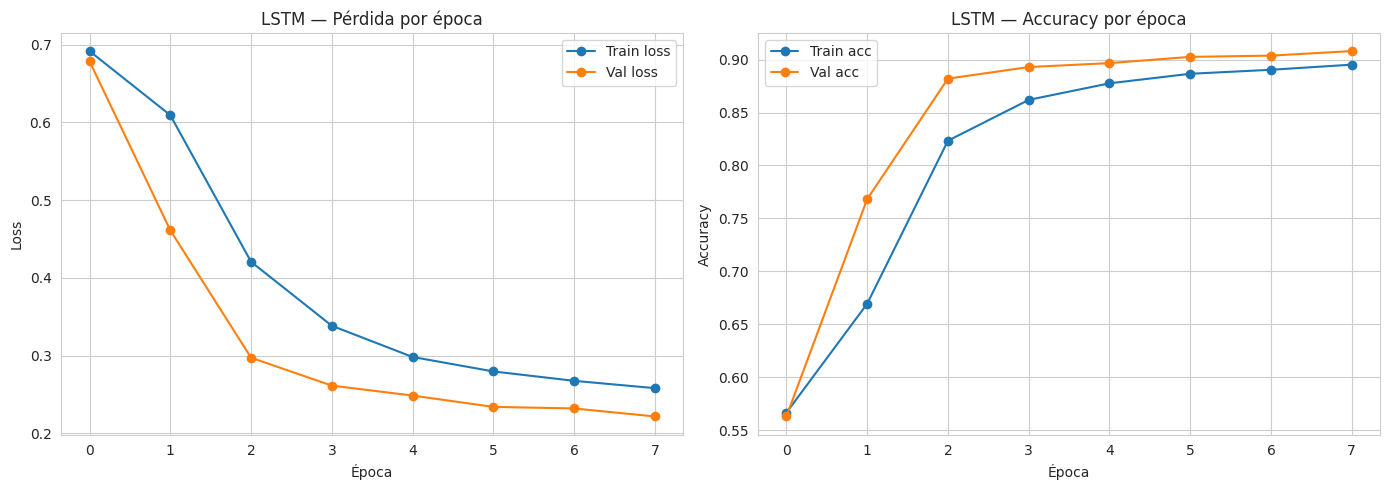

In [ ]:
# ============================================================
# CELDA 7 — GRÁFICAS de evaluación del LSTM (train vs val)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train loss', marker='o')
axes[0].plot(history.history['val_loss'], label='Val loss', marker='o')
axes[0].set_title('LSTM — Pérdida por época')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Loss'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='Train acc', marker='o')
axes[1].plot(history.history['val_accuracy'], label='Val acc', marker='o')
axes[1].set_title('LSTM — Accuracy por época')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# CELDA 8 — DistilBERT: dataset y fine-tuning
# ============================================================
# Usar texto ORIGINAL (sin stopwords removidas) para BERT
train_texts = X_train.tolist()
val_texts   = X_val.tolist()
test_texts  = X_test.tolist()

bert_tok = AutoTokenizer.from_pretrained('distilbert-base-uncased')

class YelpDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.enc = tokenizer(texts, truncation=True, padding=True, max_length=max_len)
        self.labels = labels
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item['labels'] = torch.tensor(self.labels[i])
        return item

train_ds = YelpDataset(train_texts, y_train_enc, bert_tok)
val_ds   = YelpDataset(val_texts,   y_val_enc,   bert_tok)
test_ds  = YelpDataset(test_texts,  y_test_enc,  bert_tok)

model_bert = AutoModelForSequenceClassification.from_pretrained(
    'distilbert-base-uncased', num_labels=3
)

training_args = TrainingArguments(
    output_dir='./bert_yelp',
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    logging_strategy='epoch',
    learning_rate=2e-5,
    report_to='none',
    seed=SEED,
    save_total_limit=1,
    fp16=True,
)

trainer = Trainer(
    model=model_bert, args=training_args,
    train_dataset=train_ds, eval_dataset=val_ds,
)
trainer.train()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss


In [ ]:
# ============================================================
# CELDA 9 — GRÁFICAS de evaluación de DistilBERT
# ============================================================
log = pd.DataFrame(trainer.state.log_history)
train_log = log[log['loss'].notna()] if 'loss' in log else log
eval_log  = log[log['eval_loss'].notna()] if 'eval_loss' in log else log

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pérdida
if 'loss' in train_log:
    axes[0].plot(train_log['epoch'], train_log['loss'], label='Train loss', marker='o')
if 'eval_loss' in eval_log:
    axes[0].plot(eval_log['epoch'], eval_log['eval_loss'], label='Val loss', marker='s')
axes[0].set_title('DistilBERT — Pérdida por época')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Loss'); axes[0].legend()

# Accuracy (eval_accuracy la reporta el Trainer)
if 'eval_accuracy' in eval_log:
    axes[1].plot(eval_log['epoch'], eval_log['eval_accuracy'], label='Val accuracy', marker='s')
axes[1].set_title('DistilBERT — Accuracy de validación')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# CELDA 10 — Predicciones sobre TEST (ambos modelos)
# ============================================================
# LSTM
y_pred_lstm = model_lstm.predict(X_test_seq).argmax(axis=1)

# BERT
preds_bert = trainer.predict(test_ds)
y_pred_bert = preds_bert.predictions.argmax(axis=1)

# Reportes en consola
print("="*60); print("TEST — LSTM"); print("="*60)
print("Accuracy:", accuracy_score(y_test_enc, y_pred_lstm))
print(classification_report(y_test_enc, y_pred_lstm, target_names=le.classes_))

print("="*60); print("TEST — DistilBERT"); print("="*60)
print("Accuracy:", accuracy_score(y_test_enc, y_pred_bert))
print(classification_report(y_test_enc, y_pred_bert, target_names=le.classes_))

In [ ]:
# ============================================================
# CELDA 11 — GRÁFICAS de resultados en TEST
# ============================================================
# --- 11.1 Matrices de confusión ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_enc, y_pred_lstm, display_labels=le.classes_,
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('LSTM — Matriz de confusión (test)')

ConfusionMatrixDisplay.from_predictions(
    y_test_enc, y_pred_bert, display_labels=le.classes_,
    ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('DistilBERT — Matriz de confusión (test)')
plt.tight_layout(); plt.show()

# --- 11.2 Métricas por clase (precision, recall, F1) ---
def metrics_per_class(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=range(len(le.classes_)), zero_division=0)
    return pd.DataFrame({'Precision': p, 'Recall': r, 'F1': f}, index=le.classes_)

m_lstm = metrics_per_class(y_test_enc, y_pred_lstm)
m_bert = metrics_per_class(y_test_enc, y_pred_bert)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
m_lstm.plot(kind='bar', ax=axes[0], rot=0, colormap='Blues')
axes[0].set_title('LSTM — Métricas por clase (test)')
axes[0].set_ylim(0, 1); axes[0].legend(loc='lower right')

m_bert.plot(kind='bar', ax=axes[1], rot=0, colormap='Greens')
axes[1].set_title('DistilBERT — Métricas por clase (test)')
axes[1].set_ylim(0, 1); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

# --- 11.3 Comparación global LSTM vs BERT ---
def global_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    return {'Accuracy': acc, 'Precision (macro)': p, 'Recall (macro)': r, 'F1 (macro)': f}

comp = pd.DataFrame({
    'LSTM': global_metrics(y_test_enc, y_pred_lstm),
    'DistilBERT': global_metrics(y_test_enc, y_pred_bert),
}).T

print("\nComparación global en test:\n", comp.round(4))

comp.plot(kind='bar', figsize=(10, 5), rot=0, colormap='viridis')
plt.title('Comparación global en TEST: LSTM vs DistilBERT')
plt.ylim(0, 1); plt.ylabel('Valor'); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

# --- 11.4 Distribución de predicciones vs reales ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.Series(y_test_enc).value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='gray', alpha=0.6, label='Real')
pd.Series(y_pred_lstm).value_counts().sort_index().plot(
    kind='bar', ax=axes[0], color='steelblue', alpha=0.8, label='Pred LSTM')
axes[0].set_xticks(range(len(le.classes_))); axes[0].set_xticklabels(le.classes_, rotation=0)
axes[0].set_title('Distribución real vs predicha — LSTM'); axes[0].legend()

pd.Series(y_test_enc).value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='gray', alpha=0.6, label='Real')
pd.Series(y_pred_bert).value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='seagreen', alpha=0.8, label='Pred BERT')
axes[1].set_xticks(range(len(le.classes_))); axes[1].set_xticklabels(le.classes_, rotation=0)
axes[1].set_title('Distribución real vs predicha — DistilBERT'); axes[1].legend()

plt.tight_layout(); plt.show()